# Exploratory Data Analysis (EDA)

This notebook includes the first step of building a machine learning model: exploratory data analysis.

In [73]:
# Package Imports

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

## Data Examination

The first step of course is to read and examine the data:

In [74]:
df = pd.read_csv("../data/PRSA_data.csv")
df.head()

,No,year,month,day,hour,pm2.5,DEWP,TEMP,PRES,cbwd,Iws,Is,Ir
0,1,2010,1,1,0,NaN,-21,-11.0,1021.0,NW,1.79,0,0
1,2,2010,1,1,1,NaN,-21,-12.0,1020.0,NW,4.92,0,0
2,3,2010,1,1,2,NaN,-21,-11.0,1019.0,NW,6.71,0,0
3,4,2010,1,1,3,NaN,-21,-14.0,1019.0,NW,9.84,0,0
4,5,2010,1,1,4,NaN,-20,-12.0,1018.0,NW,12.97,0,0


We immediately see that there are missing values for `pm2.5`, which is our target variable. Let's count the missing values:

In [75]:
df.info()
df.isna().sum()

<class 'pandas.DataFrame'>
RangeIndex: 43824 entries, 0 to 43823
Data columns (total 13 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   No      43824 non-null  int64  
 1   year    43824 non-null  int64  
 2   month   43824 non-null  int64  
 3   day     43824 non-null  int64  
 4   hour    43824 non-null  int64  
 5   pm2.5   41757 non-null  float64
 6   DEWP    43824 non-null  int64  
 7   TEMP    43824 non-null  float64
 8   PRES    43824 non-null  float64
 9   cbwd    43824 non-null  str    
 10  Iws     43824 non-null  float64
 11  Is      43824 non-null  int64  
 12  Ir      43824 non-null  int64  
dtypes: float64(4), int64(8), str(1)
memory usage: 4.3 MB


No          0
year        0
month       0
day         0
hour        0
pm2.5    2067
DEWP        0
TEMP        0
PRES        0
cbwd        0
Iws         0
Is          0
Ir          0
dtype: int64

We see that there are 2,067 missing values in the `pm2.5` column, which is the target variable. We will investigate this further. Next, we get an idea of the distribution of some of the variables:

In [76]:
df.describe()

,No,year,month,day,hour,pm2.5,DEWP,TEMP,PRES,Iws,Is,Ir
count,43824.000000,43824.000000,43824.000000,43824.000000,43824.000000,41757.000000,43824.000000,43824.000000,43824.000000,43824.000000,43824.000000,43824.000000
mean,21912.500000,2012.000000,6.523549,15.727820,11.500000,98.613215,1.817246,12.448521,1016.447654,23.889140,0.052734,0.194916
std,12651.043435,1.413842,3.448572,8.799425,6.922266,92.050387,14.433440,12.198613,10.268698,50.010635,0.760375,1.415867
min,1.000000,2010.000000,1.000000,1.000000,0.000000,0.000000,-40.000000,-19.000000,991.000000,0.450000,0.000000,0.000000
25%,10956.750000,2011.000000,4.000000,8.000000,5.750000,29.000000,-10.000000,2.000000,1008.000000,1.790000,0.000000,0.000000
50%,21912.500000,2012.000000,7.000000,16.000000,11.500000,72.000000,2.000000,14.000000,1016.000000,5.370000,0.000000,0.000000
75%,32868.250000,2013.000000,10.000000,23.000000,17.250000,137.000000,15.000000,23.000000,1025.000000,21.910000,0.000000,0.000000
max,43824.000000,2014.000000,12.000000,31.000000,23.000000,994.000000,28.000000,42.000000,1046.000000,585.600000,27.000000,36.000000


`pm2.5` is clearly right-skewed. The mean is about 98.6, which sits far above the median value of 72. Further, the max value of 994 is about 7 times the 75th percentile value of 137. This suggests the pollution for most hours is typical, with some being extremely high. It is worth considering a log transform on the variable to see if it yields a more symmetric distribution.

Similar behavior applies to the `Iws` column (cumulated wind speed). The mean is about 24, median is about 5.37, and max is about 585.6. These are running totals, so periods of persistent high wind likely drive this distribution. This is important to consider when choosing features for models; interpreting these values as instantaneous rates would be incorrect.

`Is` and `Ir` are a little different; as seen in `df.describe()`, at least 75% of the rows are zero. This implies that most hours, it is not raining or snowing, which is reasonable to expect. Log transforms will not fix the pile of zeros, and instead we will consider including these as "Is there precipitation?" columns or if they can be left as is.

## Addressing Missing `pm2.5` Values

Next we will examine whether the missing `pm2.5` values are dispersed randomly or if they are clumped together/exhibiting some other pattern. First, we will group the missing values by year:

In [77]:
df["pm2.5"].isna().groupby(df["year"]).sum()

year
2010    669
2011    728
2012    489
2013     82
2014     99
Name: pm2.5, dtype: int64

Most of the missing values are from 2010-2012. Now let's break it down and visualize by month.

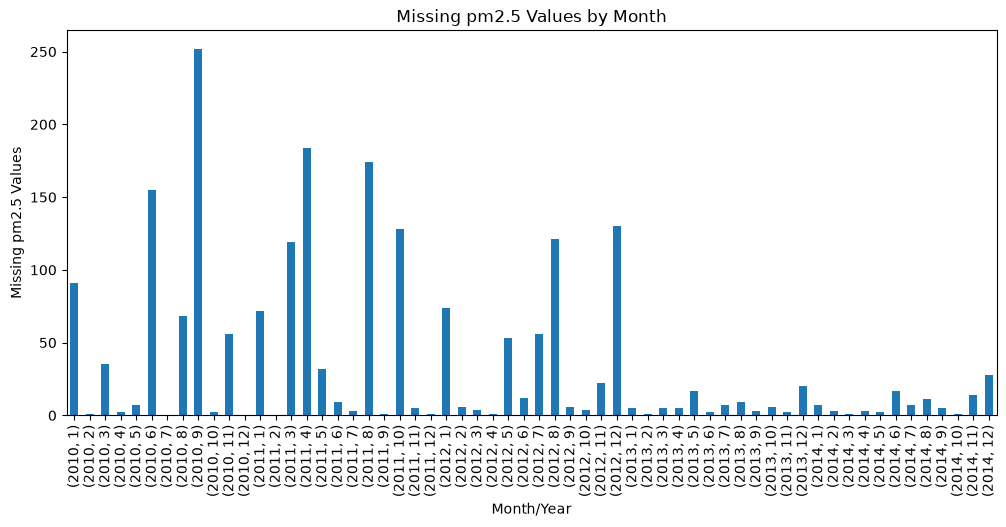

In [78]:
missing_values_by_month = df["pm2.5"].isna().groupby([df["year"], df["month"]]).sum()

missing_values_by_month.plot(kind="bar", figsize=(12, 5))
plt.title("Missing pm2.5 Values by Month")
plt.xlabel("Month/Year")
plt.ylabel("Missing pm2.5 Values")
plt.show()

All months with at least 100 missing values occur in 2012 or sooner. It's reasonable to guess that these missing values were caused by extended outages or other issues with the equipment, and that the issues were largely resolved after 2012. Let's test this theory:

In [79]:
missing_idx = df.index[df["pm2.5"].isna()]
gaps = missing_idx.to_series().diff()
gaps.value_counts().head(10)

1.0     1853
2.0       19
24.0       9
3.0        4
5.0        4
23.0       4
18.0       4
4.0        3
29.0       3
13.0       3
Name: count, dtype: int64

This shows that the vast majority of missing values come right after another missing value, meaning they come in long runs.

The next step is to determine how long each run is. This is done by assigning each run a `run_id` and grouping by it so that we can make a sum.

In [80]:
is_missing = df["pm2.5"].isna().astype(int)
run_id = (is_missing != is_missing.shift()).cumsum()
run_lengths = is_missing.groupby(run_id).sum()
run_lengths[run_lengths > 0].sort_values(ascending=False).head(10)

pm2.5
41     155
287    127
163     99
61      91
43      76
185     74
259     74
27      72
35      68
3       67
Name: pm2.5, dtype: int64

Since the data is hourly, we see that the longest stretches of missing values are 155 (~6.5 days), 127 (~5 days), 99 (~4 days), and so on.

We can sum these top 10 runs to see what share of the total missing values they make up:

In [81]:
run_lengths[run_lengths > 0].sort_values(ascending=False).head(10).sum()

np.int64(903)

Of 2,067 values, 903 of them come from a handful of long outages:

In [82]:
total_missing = df["pm2.5"].isna().sum()
run_lengths[run_lengths > 0].sort_values(ascending=False).head(10).sum()/total_missing

np.float64(0.43686502177068215)

Which is about 44% of the missing values. Come modeling time, interpolating small gaps may be reasonable, but it's not a good idea to do for stretches of several days.

Now let's look at the distribution of the run lengths:

214


<Axes: ylabel='Frequency'>

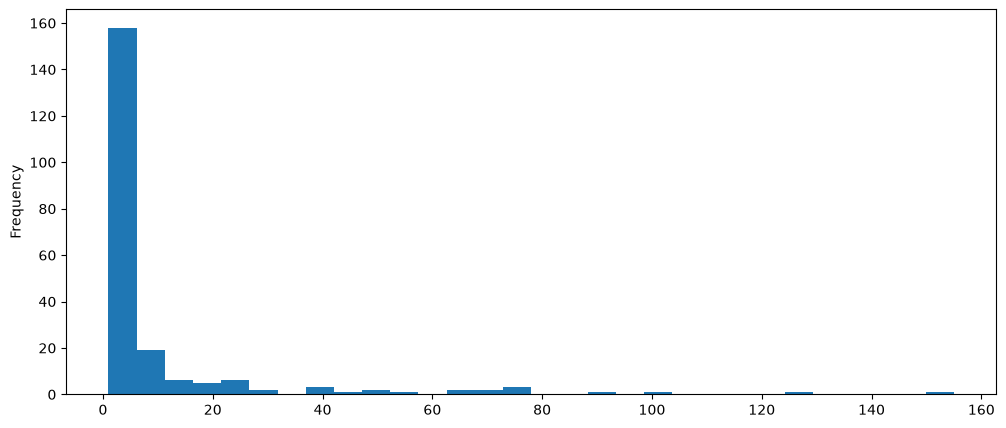

In [83]:
runs = run_lengths[run_lengths > 0]
print(len(runs))
runs.plot(kind="hist", bins=30, figsize=(12, 5))

In total, there are 214 runs. Short gaps happen often, hence the peak toward the left of the histogram. We can handle the missing values by interpolating small gaps but leaving large ones alone.

We can test possible cutoffs and see many missing hours would be covered:

In [84]:
for cutoff in [3, 6, 12, 24]:
    covered = runs[runs <= cutoff].sum()
    print(cutoff, covered, (covered/total_missing)*100)

3 176 8.514755684567005
6 250 12.094823415578132
12 435 21.04499274310595
24 726 35.12336719883889


The rightmost column above represents the percentage of missing values accounted for if we interpolate gaps of the size in the leftmost column and less. Even a generous interpolation of entire days (24) only gets us a third of the missing values.

Still, a 6-hour cutoff should be cheap to fix. For the long runs of missing values, we will either have to drop them or keep them without training on them.

## Target Variable Analysis

### Distribution

Let's revisit the distribution of `pm2.5`. We will compare the raw and log1-transformed (due to the many 0 values) distributions:

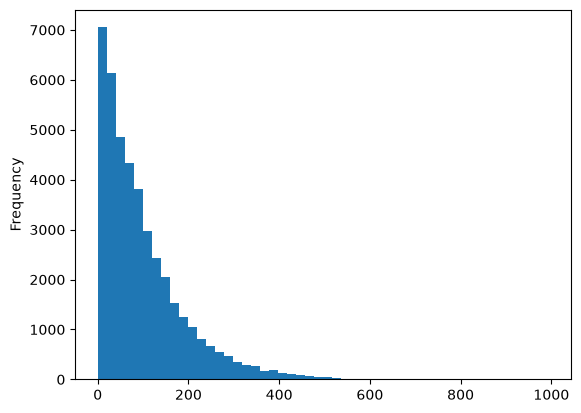

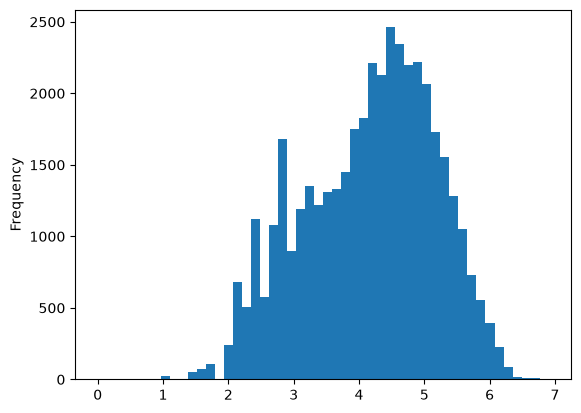

In [85]:
df["pm2.5"].plot(kind="hist", bins=50)
plt.show()

np.log1p(df["pm2.5"]).plot(kind="hist", bins=50)
plt.show()

After the transform, we see a much more symmetric distribution with an apparent slight leftward skew (which is not as pronounced as the piling at the extremes of the raw distribution).

### Pollution Over Time

Let's check out the average pollution in Beijing by month, then by hour:

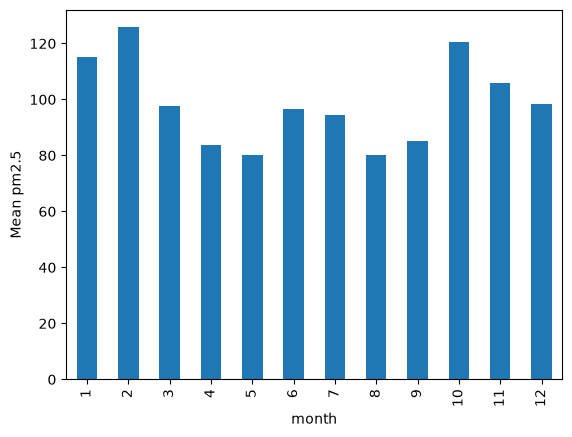

Text(0, 0.5, 'Mean pm2.5')

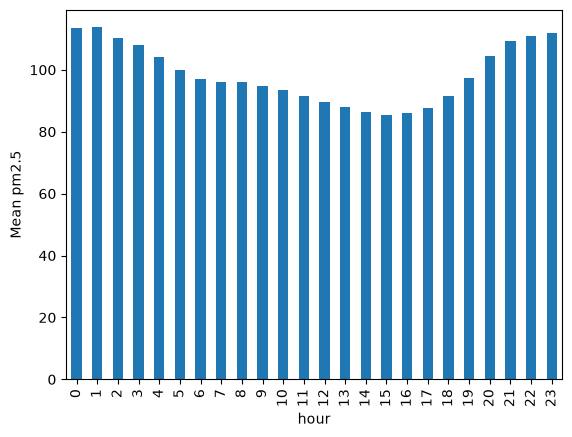

In [86]:
df.groupby("month")["pm2.5"].mean().plot(kind="bar")
plt.ylabel("Mean pm2.5")
plt.show()
df.groupby("hour")["pm2.5"].mean().plot(kind="bar")
plt.ylabel("Mean pm2.5")

The winter months generally have higher pollution, likely spurred on by an increase in heating usage. February shows a peak. December is curious, since it has a lower average pollution than its neighbors November and January. As for October and June, their spikes may be explained by particularly rough weeks (we know the right-skew of `pm2.5`) affecting the mean, given there are only 5 years of data.

By the hour, it's a smoother relationship - pollution peaks around midnight , then steadily falls until the afternoon, and then shoots up in the evening.

Let's compare the monthly means and medians.

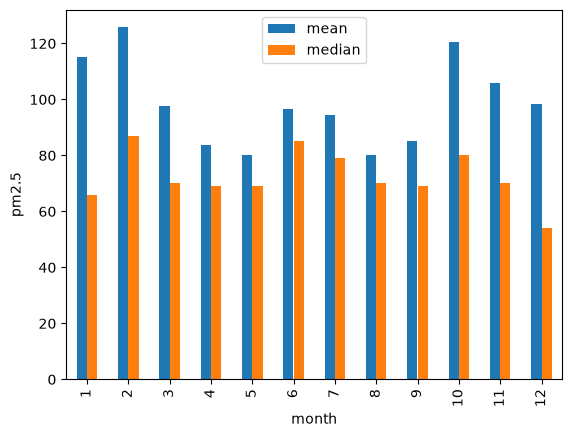

In [87]:
stats = df.groupby("month")["pm2.5"].agg(["mean", "median"])
stats.plot(kind="bar")
plt.ylabel("pm2.5")
plt.show()

Without exception, the mean is greater than the median. Let's make a monthly plot based on the median now to see if June and October were inflated or if those were part of a real seasonal pattern:

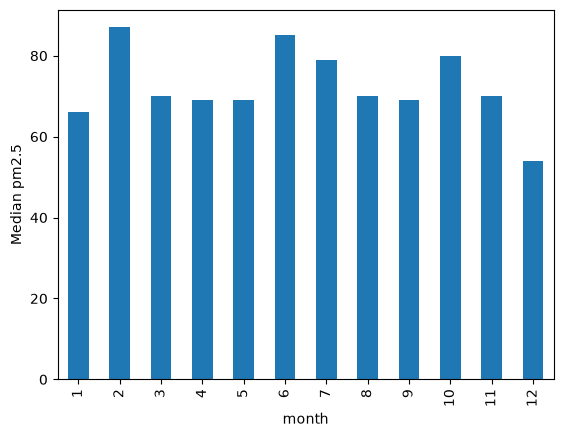

In [88]:
df.groupby("month")["pm2.5"].median().plot(kind="bar")
plt.ylabel("Median pm2.5")
plt.show()

The October/June trends persist, and we actually see the winter months' medians are relatively low. The "winter months being dirtier" hypothesis looks a bit weaker. Perhaps winter sees more spikes in `pm2.5`, which affects the mean, but are generally cleaner.

## Feature Analysis

### Wind Direction

Let's examine the wind direction feature.

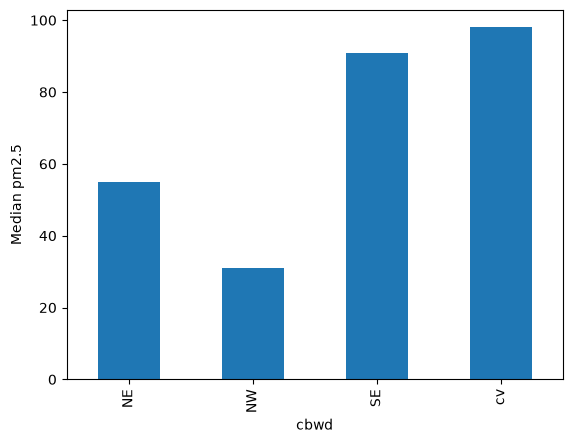

In [89]:
df.groupby("cbwd")["pm2.5"].median().plot(kind="bar")
plt.ylabel("Median pm2.5")
plt.show()

Wind direction seems like a pretty strong predictor. When the air sits mostly still (CV, "Calm and Variable"), pollution builds up. When the wind comes from the south (more industry), there is also more pollution. Wind coming from the northwest comes from Mongolia, which is not industrialized, so less pollution. We should check how many data points contributed to these bars though:

In [90]:
df["cbwd"].value_counts()

cbwd
SE    15290
NW    14150
cv     9387
NE     4997
Name: count, dtype: int64

There is plenty of data to go around, so we can trust these median values.

### Cumulated Wind Speed

`Iws` is a running total. Let's see how this looks in the table.

In [91]:
df[["cbwd", "Iws"]].head(30)

,cbwd,Iws
0,NW,1.79
1,NW,4.92
2,NW,6.71
3,NW,9.84
4,NW,12.97
5,NW,16.10
6,NW,19.23
7,NW,21.02
8,NW,24.15
9,NW,27.28


So `Iws` seems to be a cumulative sum over a stretch of hours where the wind comes from a particular direction; when `cbwd` is constant, `Iws` rises monotonically and then resets when `cbwd` changes. Let's add a column that subtracts the wind speed from the row above it to give us the actual hourly wind speed, and then verify that this pattern is correct by checking for negative values.

In [92]:
run_id = (df["cbwd"] != df["cbwd"].shift()).cumsum()
df["Iws_hourly"] = df.groupby(run_id)["Iws"].diff().fillna(df["Iws"])

In [93]:
(df["Iws_hourly"] < 0).sum()

np.int64(0)

We are in the clear with no negative wind speeds.

### Other Numeric Features

For the other features, we will plot them with `pm2.5`, so let's first plot the monthly average `pm2.5` over the whole time period to see the general trend.

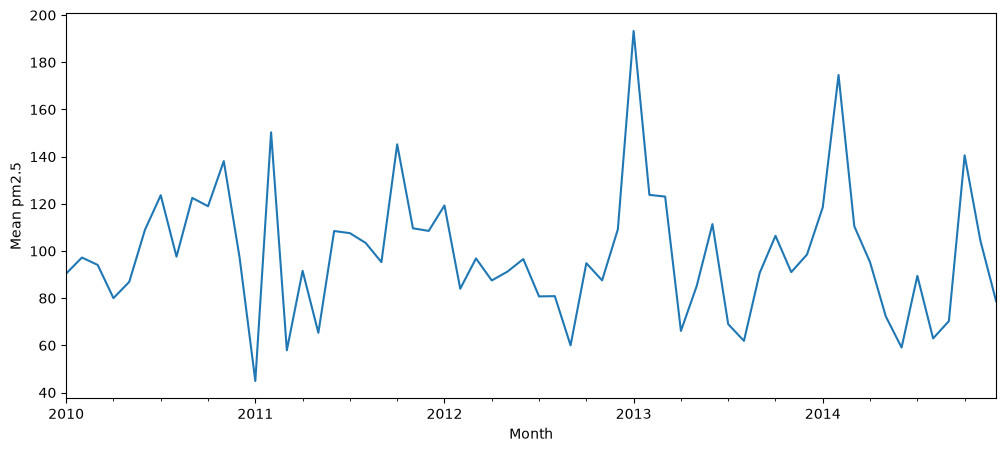

In [94]:
df["datetime"] = pd.to_datetime(df[["year", "month", "day", "hour"]])
monthly = df.set_index("datetime")["pm2.5"].resample("ME").mean()
monthly.plot(figsize=(12, 5))
plt.ylabel("Mean pm2.5")
plt.xlabel("Month")
plt.show()

Winter peaks are evident in 2013 and 2014, but there is a big drop at the new year in 2011. We did see that the earlier years had more missing data, so this could possibly be explained by that. Let's see how many non-missing hours are present among the months.

In [95]:
counts = df.set_index("datetime")["pm2.5"].resample("ME").count()
print(counts["2010-10":"2011-04"])

datetime
2010-10-31    742
2010-11-30    664
2010-12-31    744
2011-01-31    672
2011-02-28    672
2011-03-31    625
2011-04-30    536
Freq: ME, Name: pm2.5, dtype: int64


These months have a lot of data still, which means that December 2010 was genuinely a clean month. This clean December may be part of why the median `pm2.5` for all Decembers was rather low. Likewise, the spike the very next month has plenty of data behind it, so it shouldn't be dismissed as not real.

We saw that wind direction seems to affect pollution the most, so perhaps December 2010 had a lot of northwesterly wind. Let's find out.

In [96]:
dec = df[(df["year"] == 2010) & (df["month"] == 12)]
dec["cbwd"].value_counts()

cbwd
NW    424
cv    122
SE    107
NE     91
Name: count, dtype: int64

Sure enough, over half of the hours for December had wind from the northwest, which we found to be the cleanest wind direction. While this is only one month, it seems to support our hypothesis that wind direction is a very important feature. That said, there are still other weather features at play, and we'll check the correlation between them and `pm2.5` next.

In [97]:
df["log_pm"] = np.log1p(df["pm2.5"])
cols = ["log_pm", "DEWP", "TEMP", "PRES", "Iws_hourly", "Is", "Ir"]
df[cols].corr()

,log_pm,DEWP,TEMP,PRES,Iws_hourly,Is,Ir
log_pm,1.000000,0.312648,0.017029,-0.158155,-0.478039,0.033205,-0.049841
DEWP,0.312648,1.000000,0.824633,-0.778346,-0.326763,-0.034410,0.125090
TEMP,0.017029,0.824633,1.000000,-0.826690,-0.025544,-0.092601,0.049121
PRES,-0.158155,-0.778346,-0.826690,1.000000,0.090147,0.069028,-0.079843
Iws_hourly,-0.478039,-0.326763,-0.025544,0.090147,1.000000,-0.016451,0.014206
Is,0.033205,-0.034410,-0.092601,0.069028,-0.016451,1.000000,-0.009548
Ir,-0.049841,0.125090,0.049121,-0.079843,0.014206,-0.009548,1.000000


Looking at the `log_pm` row first (log-transformed `pm2.5`), the feature with the strongest simple linear correlation is the hourly wind speed, which is negative and has size about 0.48; this makes sense because the stronger the wind, the more pollutants get dispersed. The next largest correlation is a positive one with dewpoint, presumably because higher humidity traps pollutants.

We see some strong correlation between features as well, which makes sense with weather data. The triumvirate of dewpoint, temperature, and pressure move with each other (not in the same direction though - pressure and dewpoint have a negative correlation). This is important to know when picking features for the models.